In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.base import clone
from xgboost import XGBRegressor
import seaborn as sns
from reg_helper import *
from plots import *
import random

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.base import clone


In [11]:
# Необходимо для корректной работы внешних .py файлов
# %load_ext autoreload
# %autoreload 2
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

In [12]:
data = pd.read_csv('diamonds.csv')
df_preprocessed = data.copy()
print(df_preprocessed.shape)

df_preprocessed = df_preprocessed.drop(['Unnamed: 0'], axis=1)
df_preprocessed.drop_duplicates(inplace=True) #удалим дубликаты
df_preprocessed = df_preprocessed[(df_preprocessed[['x', 'y', 'z']] != 0).all(axis=1)].copy()


df_preprocessed['depth_counted'] = df_preprocessed['z'] * 2 / (df_preprocessed['x'] + df_preprocessed['y']) * 100
df_preprocessed['depth_diff'] = abs(df_preprocessed['depth'] - df_preprocessed['depth_counted'])
index_to_drop = df_preprocessed[df_preprocessed['depth_diff'] > 1].index
df_preprocessed = df_preprocessed.drop(index=index_to_drop)
df_preprocessed.drop(['depth_counted', 'depth_diff'], axis=1, inplace=True)

df_preprocessed.shape

(53940, 11)


(53695, 10)

In [23]:
ordered_categories = {
    'cut': ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],
    'color': ['J', 'I', 'H', 'G', 'F', 'E', 'D'],
    'clarity': ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
}
numeric_features = ['carat', 'depth', 'table', 'x', 'y', 'z']

preprocessor = ColumnTransformer(
    transformers=[
        ('ordinal_encoder',
         OrdinalEncoder(categories=[
             ordered_categories['cut'],
             ordered_categories['color'],
             ordered_categories['clarity']
         ]),
         list(ordered_categories.keys())),

        ('num', 'passthrough', numeric_features)
    ],
    verbose_feature_names_out=False
)

preprocessor.set_output(transform="pandas")

preprocessor.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal_encoder', ...), ('num', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per tran

In [24]:
X, y = divide_data(df_preprocessed, 'price')

In [25]:
models = [
    ('LinearRegression', LinearRegression()),
    ('DecisionTreeRegressor', DecisionTreeRegressor(random_state=SEED, max_depth=10)),
    ('RandomForestRegressor', RandomForestRegressor(random_state=SEED)),
    ('LGBMRegressor', LGBMRegressor(random_state=SEED))
]

In [26]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001333 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1277
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000378 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1277
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 3931.629202
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001022 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Tota

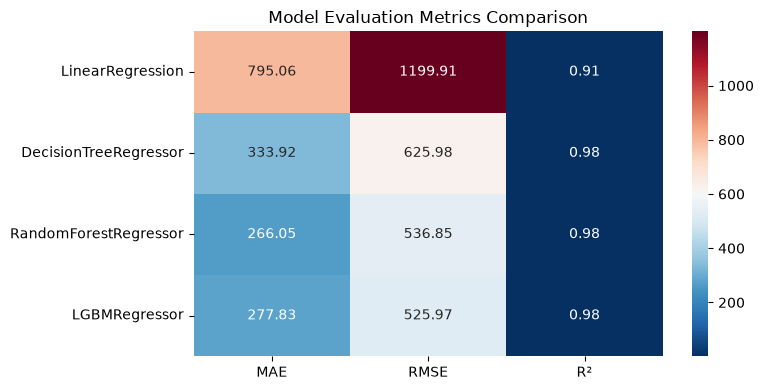

In [27]:
initial_metrics = train_evaluate_models_cv(
    models=models,
    X=X,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)


# Feature Engineering

## Add feature volume

Попробуем добавить новую фичу, которая отвечает за объём бриллианта.

In [13]:
X_volume = X.copy()

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007222 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1536
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007229 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1539
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3931.629202
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007466 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1538
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Sta

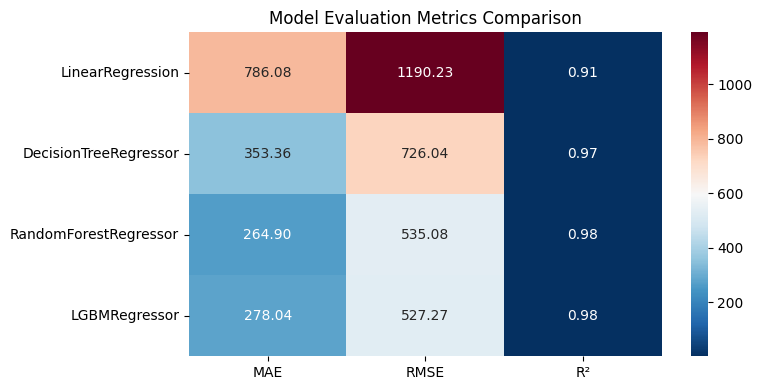

In [14]:
X_volume['volume'] = X_volume['x'] * X_volume['y'] * X_volume['z']

preprocessor_volume = clone(preprocessor)

preprocessor_volume.set_params(
    column_transformer__transformers=[
        (
            'ordinal_encoder',
            OrdinalEncoder(categories=[
                ordered_categories['cut'],
                ordered_categories['color'],
                ordered_categories['clarity']
            ]),
            list(ordered_categories.keys())
        ),
        (
            'num',
            StandardScaler(),
            numeric_features + ['volume']
        )
    ]
)

volume_metric = train_evaluate_models_cv(
    models=models,
    X=X_volume,
    y=y,
    preprocessor=preprocessor_volume,
    cv=cv,
    seed=SEED
)


(<Figure size 800x400 with 2 Axes>,
                             MAE      RMSE        R²
 LinearRegression      -8.981553 -9.677566  0.001458
 DecisionTreeRegressor -1.991377 -0.288897  0.000027
 RandomForestRegressor -1.142898 -1.768290  0.000121
 LGBMRegressor          0.214844  1.291467 -0.000086)

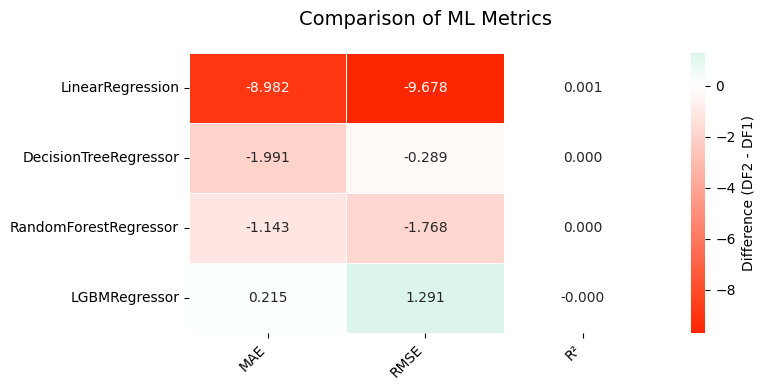

In [15]:
compare_metrics_heatmap(initial_metrics, volume_metric)

Как можно заметить, подобный признак не дал сильного улучшения по метрикам: в линейной регрессии ошибка снизилась, однако у остальных моделей результат получился нестабильный.

## Carat ** 2
Попробуем добавить признак = carat**2

In [16]:
X_squared_carat = X.copy()

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001328 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1527
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001345 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1533
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3931.629202
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001342 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not

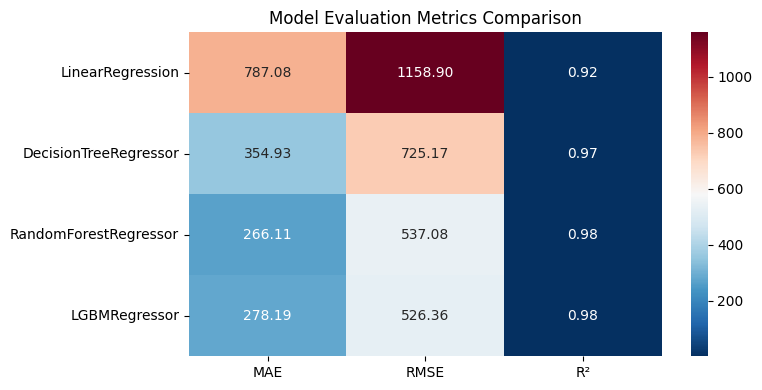

In [17]:
X_squared_carat['carat_squared'] = X_squared_carat['carat'] ** 2

preprocessor_squared_carat = clone(preprocessor)

preprocessor_squared_carat.set_params(
    column_transformer__transformers=[
        (
            'ordinal_encoder',
            OrdinalEncoder(categories=[
                ordered_categories['cut'],
                ordered_categories['color'],
                ordered_categories['clarity']
            ]),
            list(ordered_categories.keys())
        ),
        (
            'num',
            StandardScaler(),
            numeric_features + ['carat_squared']
        )
    ]
)

squared_carart_metric = train_evaluate_models_cv(
    models=models,
    X=X_squared_carat,
    y=y,
    preprocessor=preprocessor_squared_carat,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                             MAE       RMSE        R²
 LinearRegression      -7.975872 -41.009763  0.006097
 DecisionTreeRegressor -0.421455  -1.163097  0.000101
 RandomForestRegressor  0.064714   0.225258 -0.000014
 LGBMRegressor          0.358464   0.387109 -0.000025)

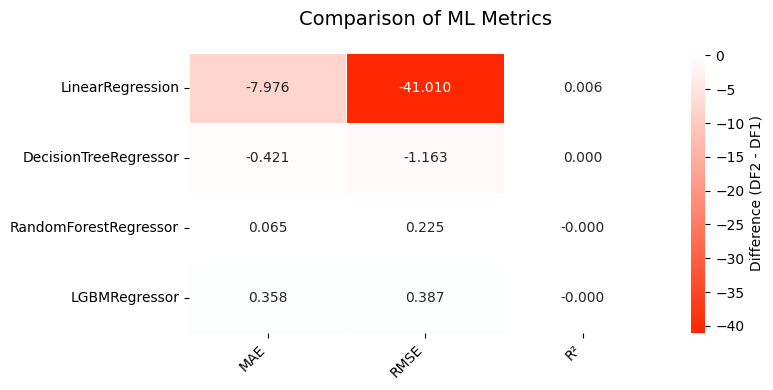

In [18]:
compare_metrics_heatmap(initial_metrics, squared_carart_metric)

Этот признак дал заметное улучшение для линейной регрессии, сильно снизил RMSE, однако практически не повлиял на результат других моделей. Это связано с тем, что остальные модели умеют работать с нелинейными данными, в отличие от линейной регрессии.

## Плотность бриллианта

In [19]:
X_density_proxy = X.copy()
X_density_proxy['density_proxy'] = X['carat'] / (
    X['x'] * X['y'] * X['z']
)

preprocessor_density = clone(preprocessor)
preprocessor_density.set_params(
    column_transformer__transformers=[
        (
            'ordinal_encoder',
            OrdinalEncoder(categories=[
                ordered_categories['cut'],
                ordered_categories['color'],
                ordered_categories['clarity']
            ]),
            list(ordered_categories.keys())
        ),
        (
            'num',
            StandardScaler(),
            numeric_features + ['density_proxy']
        )
    ]
)

Pipeline(steps=[('column_transformer',
                 ColumnTransformer(transformers=[('ordinal_encoder',
                                                  OrdinalEncoder(categories=[['Fair',
                                                                              'Good',
                                                                              'Very '
                                                                              'Good',
                                                                              'Premium',
                                                                              'Ideal'],
                                                                             ['J',
                                                                              'I',
                                                                              'H',
                                                                              'G',
                                                                              'F',
                                                                              'E',
                                                                              'D'],
                                                                             ['I1',
                                                                              'SI2',
                                                                              'SI1',
                                                                              'VS2',
                                                                              'VS1',
                                                                              'VVS2',
                                                                              'VVS1',
                                                                              'IF']]),
                                                  ['cut', 'color', 'clarity']),
                                                 ('num', StandardScaler(),
                                                  ['carat', 'depth', 'table',
                                                   'x', 'y', 'z',
                                                   'density_proxy'])],
                                   verbose_feature_names_out=False))])

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004348 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1536
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001360 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1539
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3931.629202
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001318 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] To

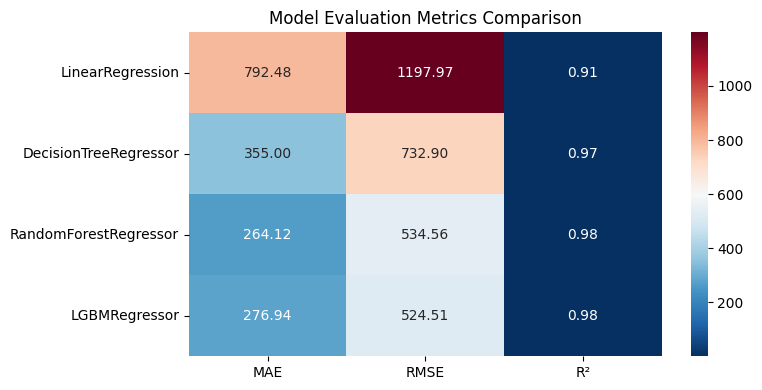

In [20]:
density_metric = train_evaluate_models_cv(
    models=models,
    X=X_density_proxy,
    y=y,
    preprocessor=preprocessor_density,
    cv=cv,
    seed=SEED
)


(<Figure size 800x400 with 2 Axes>,
                             MAE      RMSE        R²
 LinearRegression      -2.584933 -1.937662  0.000293
 DecisionTreeRegressor -0.355564  6.568800 -0.000610
 RandomForestRegressor -1.925406 -2.289547  0.000156
 LGBMRegressor         -0.889663 -1.461714  0.000097)

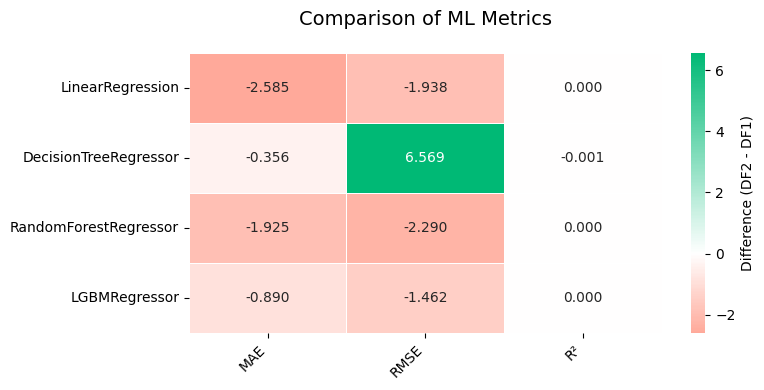

In [21]:
compare_metrics_heatmap(initial_metrics, density_metric)

Добавление признака плотности позволило немного снизить ошибки большинства моделей, однако для решающего дерева, наоборот, привело к заметному ухудшению метрик. Возможно, новый признак повлиял на выбор разбиений дерева, в результате чего его обобщающая способность снизилась.

# Анализ ошибок модели, взятие логарифма от таргета

Проанализируем как распределены ошибки у LightGBM

In [25]:
model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', LGBMRegressor(random_state=SEED))
])

y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001223 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1277
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001224 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1277
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 3931.629202
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001203 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not e

In [26]:
errors_df = X.copy()
errors_df['y_true'] = y
errors_df['y_pred'] = y_pred
errors_df['error'] = errors_df['y_true'] - errors_df['y_pred']
errors_df['abs_error'] = errors_df['error'].abs()

In [27]:
errors_df.head()

,carat,cut,color,clarity,depth,table,x,y,z,y_true,y_pred,error,abs_error
0,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,2.43,326,540.725030,-214.725030,214.725030
1,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,2.31,326,563.987058,-237.987058,237.987058
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,2.31,327,462.523876,-135.523876,135.523876
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,2.63,334,480.721850,-146.721850,146.721850
4,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,2.75,335,417.567660,-82.567660,82.567660


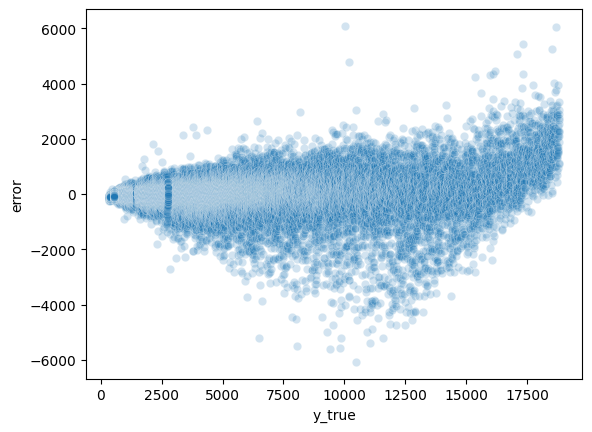

In [28]:
sns.scatterplot(
    data=errors_df,
    x='y_true',
    y='error',
    alpha=0.2
)

plt.show()

Дисперсия ошибок не постоянна, с ростом цены она расширяется. Это называется гетероскедастичностью. Один из способов борьбы с ней - это взять логарифм от таргета.

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001235 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1277
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 7.787542
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001221 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1277
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 7.785980
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001223 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough,

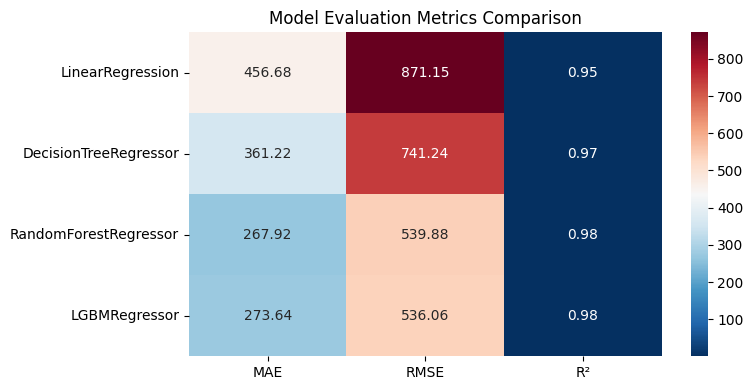

In [32]:
from sklearn.compose import TransformedTargetRegressor


models_log = [
    (
        name,
        TransformedTargetRegressor(
            regressor=model,
            func=np.log,
            inverse_func=np.exp
        )
    )
    for name, model in models
]

log_metrics = train_evaluate_models_cv(
    models=models_log,
    X=X,
    y=y,
    preprocessor=preprocessor,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                               MAE        RMSE        R²
 LinearRegression      -338.378377 -328.766372  0.042889
 DecisionTreeRegressor    5.864057   14.914243 -0.001373
 RandomForestRegressor    1.874985    3.029730 -0.000204
 LGBMRegressor           -4.182805   10.083596 -0.000672)

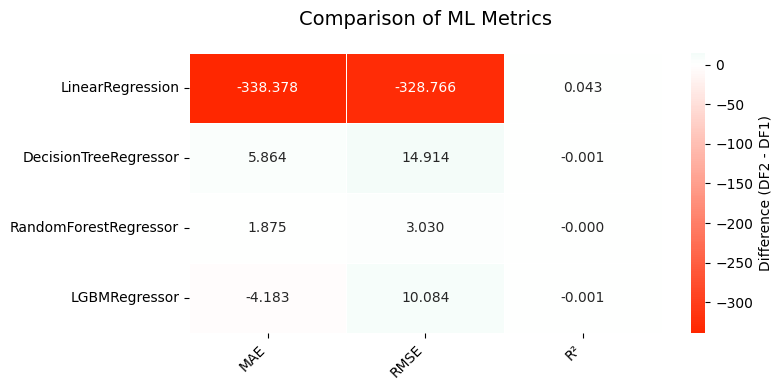

In [33]:
compare_metrics_heatmap(initial_metrics, log_metrics)

Подобный подход улучшил метрики только у LinearRegression. У остальных моделей ситуация стала немного хуже.

# Delete x, y, z features

In [32]:
X_exp = X.copy()
X_exp = X_exp.drop(columns=['x', 'y', 'z'])

interval columns not set, guessing: ['carat', 'depth', 'table']


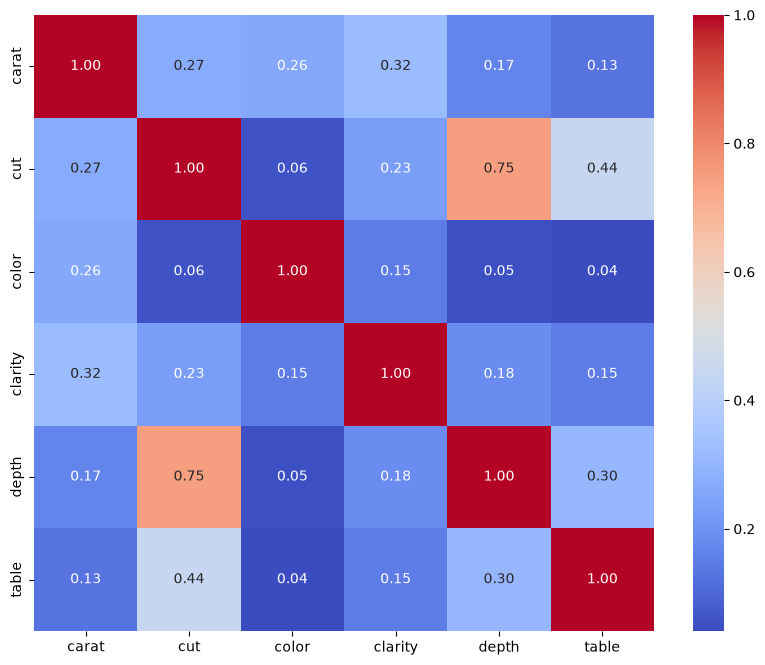

In [33]:
plot_phik(X_exp)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000204 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 512
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 6
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000176 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 512
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 6
[LightGBM] [Info] Start training from score 3931.629202
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000235 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not eno

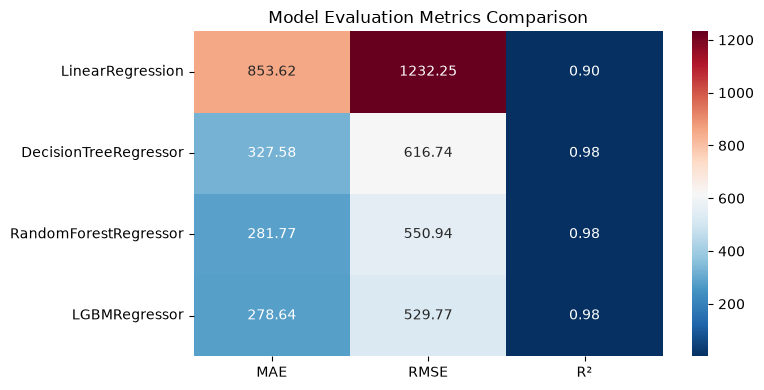

In [ ]:
preprocessor_del_exp = clone(preprocessor)

preprocessor_del_exp.set_params(
    transformers=[
        (
            'ordinal_encoder',
            OrdinalEncoder(categories=[
                ordered_categories['cut'],
                ordered_categories['color'],
                ordered_categories['clarity']
            ]),
            list(ordered_categories.keys())
        ),
        (
            'num',
            'passthrough',
            ['carat', 'depth', 'table']
        )
    ]
)
exp_del_xyz_metrics = train_evaluate_models_cv(
    models=models,
    X=X_exp,
    y=y,
    preprocessor=preprocessor_del_exp,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                              MAE       RMSE        R²
 LinearRegression       58.556938  32.334091 -0.004949
 DecisionTreeRegressor  -6.342579  -9.238315  0.000717
 RandomForestRegressor  15.721312  14.089508 -0.000969
 LGBMRegressor           0.814041   3.793311 -0.000253)

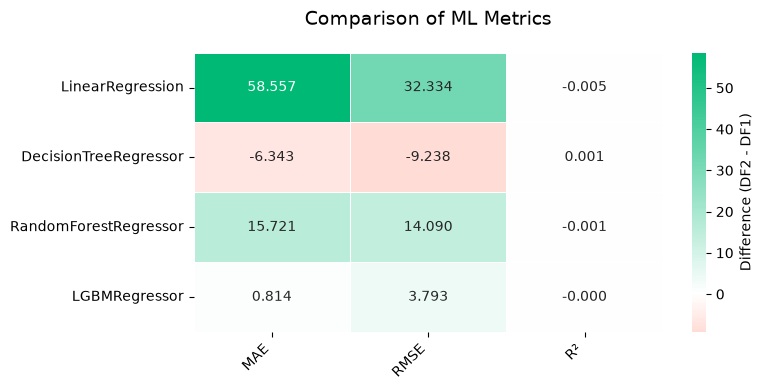

In [39]:
compare_metrics_heatmap(initial_metrics, exp_del_xyz_metrics)

Удаление сильно коррелирующих признаков x, y, z нисколько не улучшило метрики. 

# One-hot encoding for 'cut'

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000336 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 517
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000280 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 517
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 10
[LightGBM] [Info] Start training from score 3931.629202
[LightGBM] [Warning] Fou

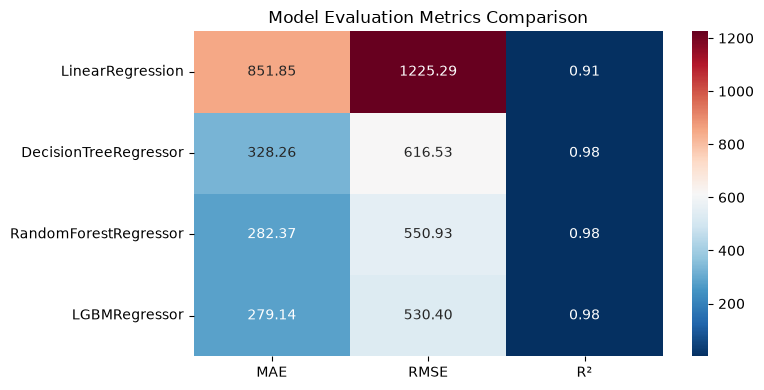

In [40]:
X_cut_encoding = X.copy()
preprocessor_cut_enc = clone(preprocessor)
ordered_categories = {
    'color': ['J', 'I', 'H', 'G', 'F', 'E', 'D'],
    'clarity': ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
}
preprocessor_cut_enc.set_params(
    transformers=[
        (
            'ordinal_encoder',
            OrdinalEncoder(categories=[
                ordered_categories['color'],
                ordered_categories['clarity']
            ]),
            ['color', 'clarity']
        ),
        (
            'one_hot',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            ['cut']
        ),
        (
            'num',
            'passthrough',
            numeric_features
        )
    ]
)
cut_encoding_exp_metrics = train_evaluate_models_cv(
    models=models,
    X=X_cut_encoding,
    y=y,
    preprocessor=preprocessor_cut_enc,
    cv=cv,
    seed=SEED
)

(<Figure size 800x400 with 2 Axes>,
                              MAE       RMSE        R²
 LinearRegression       56.786362  25.375355 -0.003872
 DecisionTreeRegressor  -5.664827  -9.449345  0.000733
 RandomForestRegressor  16.326551  14.078697 -0.000967
 LGBMRegressor           1.315087   4.424155 -0.000297)

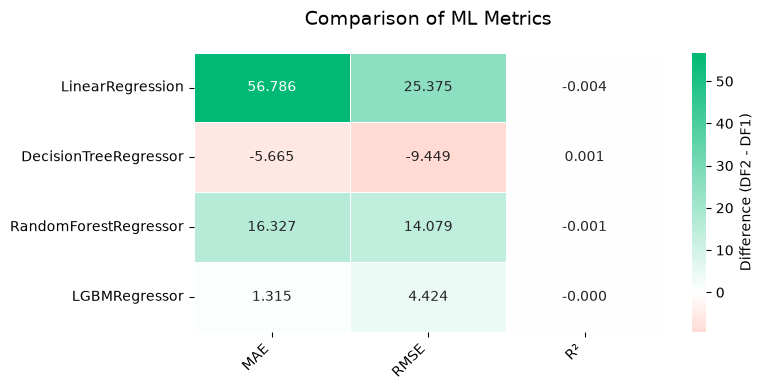

In [41]:
compare_metrics_heatmap(initial_metrics, cut_encoding_exp_metrics)

Оne-hot кодирование по результатам не показало, что оно лучше чем label encoding для признака cut.